# Reefugia: multi-year DHW trend
How is reef heat stress changing? Annual maximum Degree Heating Weeks from
NOAA Coral Reef Watch (5 km), with a regional trend and a per-pixel trend map.

The CRW record starts on 1985-04-01, so 1986 is the first full year.
The data are NOAA's ready-made annual maximum DHW files, one per year, cut to the
region and cached in `data/crw/` (a few minutes to download the first time).

In [1]:
import matplotlib.pyplot as plt

from reefugia import trend, visualise
from reefugia.fetch import REGIONS

REGION     = "red_sea"   # options: coral_triangle, andaman_sea, great_barrier_reef, red_sea
START_YEAR = 1986        # first full year of the CRW record
END_YEAR   = 2025        # last complete year
DEGREE     = 1           # 1 = linear trend
PLACE      = visualise.pretty_region(REGION)

print(f"Region bounds: {REGIONS[REGION]}")

Region bounds: {'min_lon': 32.0, 'max_lon': 43.5, 'min_lat': 12.0, 'max_lat': 30.0}


## 1. Annual maximum DHW per pixel

In [2]:
dhw_annual = trend.load_or_fetch_crw_annual_max(REGION, START_YEAR, END_YEAR)
dhw_annual

<xarray.DataArray 'dhw' (year: 40, latitude: 360, longitude: 230)> Size: 26MB
dask.array<open_dataset-dhw, shape=(40, 360, 230), dtype=float64, chunksize=(10, 180, 115), chunktype=numpy.ndarray>
Coordinates:
  * year       (year) int64 320B 1986 1987 1988 1989 ... 2022 2023 2024 2025
  * latitude   (latitude) float32 1kB 12.02 12.07 12.12 ... 29.88 29.92 29.98
  * longitude  (longitude) float32 920B 32.03 32.08 32.12 ... 43.38 43.42 43.47
Attributes:
    coverage_content_type:  physicalMeasurement
    grid_mapping:           crs
    long_name:              degree heating week
    standard_name:          N/A
    units:                  degree_Celsius_weeks
    valid_max:              10000
    valid_min:              0

Worst year: 2023 (12.6 °C-weeks)


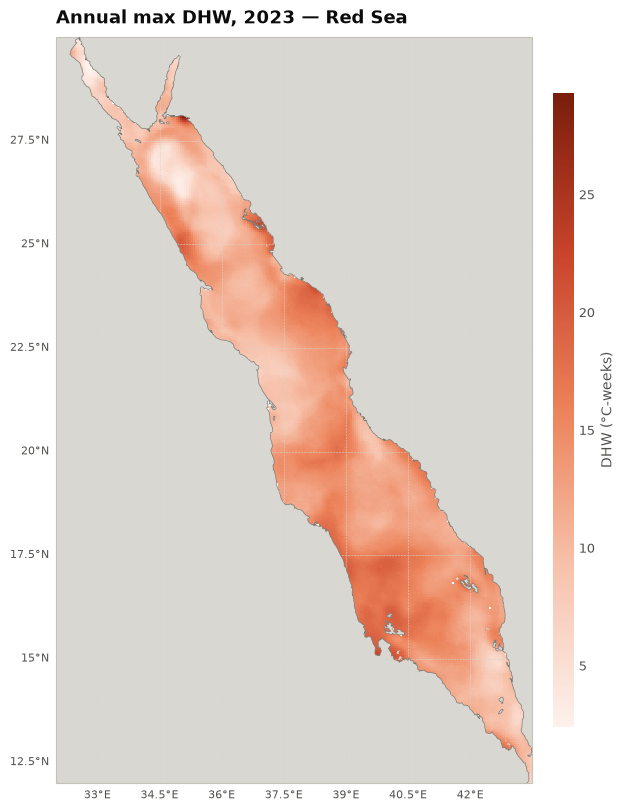

In [3]:
# regional (area-weighted) mean of annual max DHW, and the worst year
regional = trend.area_weighted_mean(dhw_annual)
peak_year = int(regional.idxmax("year"))
print(f"Worst year: {peak_year} ({float(regional.max()):.1f} °C-weeks)")

fig = visualise.plot_map(dhw_annual.sel(year=peak_year), "DHW (°C-weeks)",
                         title=f"Annual max DHW, {peak_year} — {PLACE}")
plt.show()

## 2. Regional trend
Polynomial fit to the area-weighted regional mean of annual max DHW.
For a linear fit the slope is reported per decade.

In [4]:
fit = trend.fit_trend(dhw_annual, degree=DEGREE)

print(f"R² = {fit['r2']:.2f}")
if DEGREE == 1:
    slope = fit["model"].named_steps["linearregression"].coef_[1]
    print(f"Slope = {slope * 10:.2f} °C-weeks per decade")

R² = 0.35
Slope = 1.40 °C-weeks per decade


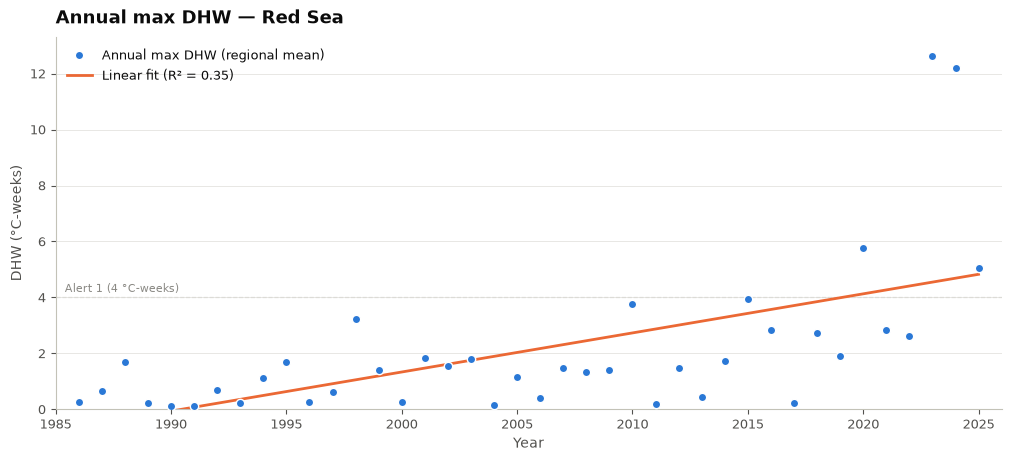

In [5]:
fig = visualise.plot_trend(fit, region_name=REGION)
plt.show()

## 3. Per-pixel trend map
Slope of annual max DHW at each pixel (°C-weeks per year). Fits one model per
pixel, so this is slow for large regions.

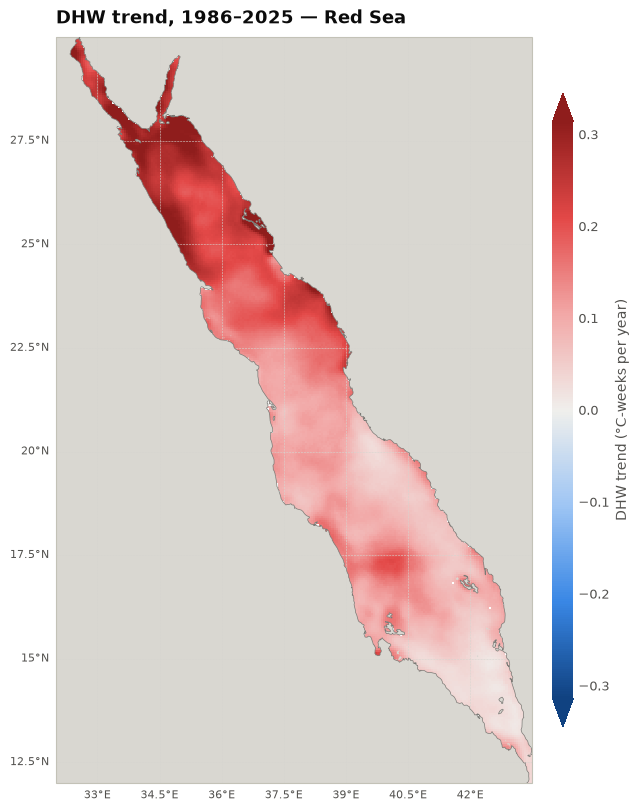

In [6]:
slope_map = trend.pixel_trend(dhw_annual, degree=DEGREE)
fig = visualise.plot_trend_map(slope_map, title=f"DHW trend, {START_YEAR}–{END_YEAR} — {PLACE}")
plt.show()

## Notes
- Annual max DHW is dominated by El Niño years, so R² is expected to be modest
  and the trend says nothing about any particular future year.
- CRW's own trend product covers SST, not DHW
  ([Thermal History](https://coralreefwatch.noaa.gov/product/thermal_history/)).
- NOAA's annual files were checked against the maximum of their daily DHW
  (1986–2025, Red Sea, 11 Nov 2026). Every pixel agreed within 0.01 °C-weeks and the
  regional trend was 1.396 vs 1.397 °C-weeks per decade, so the much slower daily
  download isn't needed. The only difference was about 14 pixels a year on the
  region's edge, where the two sources cut the boundary slightly differently.